# **Final project: Intelligent Medical Image Classification**
**Melanoma detection using a custom CNN**

*Authors:*

*   Camila García Vázquez **2177743**
*   Alan Zahir Lopez Rodriguez **2103115**
*   Ezequiel Sandoval Puerto **2061522**
*   Arleth Cassandra Andrade Cordova **1896113**

*Class schedule:* Thursday N3-N6

Dataset: "*Skin Cancer: Malignant vs. Benign*"

https://www.kaggle.com/datasets/fanconic/skin-cancer-malignant-vs-benign/data

# **2. Implementation and Development**

**Importing all libraries and dataset downloading**

In [1]:
# Import all libraries
import os
import kagglehub
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files
from tensorflow.keras import layers, models
from tensorflow.keras.preprocessing import image as keras_image
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

# Download dataset from kaggle
path = kagglehub.dataset_download("fanconic/skin-cancer-malignant-vs-benign")

# Print path to dataset
print("Path to dataset files:", path)

# Organize internal path according to data explorer in kaggle
data_dir = os.path.join(path, "data") if os.path.exists(os.path.join(path, "data")) else path

100%|██████████| 325M/325M [00:05<00:00, 63.2MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/fanconic/skin-cancer-malignant-vs-benign/versions/4


**Scanning folders, dataset cleaning and construction**

In [2]:
# Define function to scan a folder (train or test), set path and set a list with all valid images
def build_cleaned_dataframe(subset_folder):
    target_path = os.path.join(data_dir, subset_folder)
    records = []

    # Scanning "benign" and "malign" folders from the dataset
    for category in ['benign', 'malignant']:
      class_path = os.path.join(target_path, category)
      if not os.path.exists(class_path):
        continue

      for filename in os.listdir(class_path):
        if filename.lower().endswith(('.jpg', '.jpeg', '.png')):
          full_path = os.path.join(class_path, filename)

          # Data cleaning
          if os.path.getsize(full_path) > 0:
            records.append({
              'filepath': full_path,
              'class_name': category
            })

    # Convert clean data to a pandas df
    df = pd.DataFrame(records)

    # Codification using scikit-learn
    le = LabelEncoder()
    df['label'] = le.fit_transform(df['class_name']) # benign -> 0, malignant -> 1

    print(f"Total clean images in '{subset_folder}': {len(df)}")
    return df

# Combine pre-existing folders into a single unified df
df_full = pd.concat([build_cleaned_dataframe('train'), build_cleaned_dataframe('test')], ignore_index=True)

# Partition into an 80/20 training/testing rate using stratified sampling
df_train, df_test = train_test_split(
    df_full,
    test_size=0.20,
    random_state=42,
    stratify=df_full['label'] # Makes sure an exact 50/50 class balance is maintained in both sets
)

print(f"Total dataset images: {len(df_full)}")
print(f"Training set (80%): {len(df_train)} images")
print(f"Testing set (20%): {len(df_test)} images")

Total clean images in 'train': 2637
Total clean images in 'test': 660
Total dataset images: 3297
Training set (80%): 2637 images
Testing set (20%): 660 images


**A. Data preprocessing**

In [3]:
# Set image and batch size
img_size = 224, 224
batch_size = 32

# Read images with TensorFlow using pandas path (file_path)
def load_and_decode_image(file_path, label):
    img = tf.io.read_file(file_path)
    img = tf.image.decode_jpeg(img, channels=3)
    # Just to make sure all images are 224x224
    img = tf.image.resize(img, img_size)
    return img, label

# Set efficient data loaders tf.data via pandas df
train_ds = tf.data.Dataset.from_tensor_slices((df_train['filepath'].values, df_train['label'].values))
train_ds = train_ds.map(load_and_decode_image).shuffle(1000).batch(batch_size)

test_ds = tf.data.Dataset.from_tensor_slices((df_test['filepath'].values, df_test['label'].values))
test_ds = test_ds.map(load_and_decode_image).batch(batch_size)

# Define augmentation layers (applied only to training images)
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.1),
])

# Scale normalization
rescaling_layer = layers.Rescaling(1./255)

# Apply augmentation + [0,1] scale to train_ds, and ONLY scale to test_ds
train_ds = train_ds.map(lambda x, y: (data_augmentation(x, training=True), y))
train_ds = train_ds.map(lambda x, y: (rescaling_layer(x), y)).prefetch(buffer_size=tf.data.AUTOTUNE)

test_ds = test_ds.map(lambda x, y: (rescaling_layer(x), y)).prefetch(buffer_size=tf.data.AUTOTUNE)

"""
# Scale normalization
rescaling_layer = layers.Rescaling(1./255)

# Apply [0,1] scale and optimize GPU memory buffer
train_ds = train_ds.map(lambda x, y: (rescaling_layer(x), y)).prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds = test_ds.map(lambda x, y: (rescaling_layer(x), y)).prefetch(buffer_size=tf.data.AUTOTUNE)

# Quick note: resizing was not necessary as all the dataset images are already the same size, but we used tf.image.resize to make sure all images are resized
"""

'\n# Scale normalization\nrescaling_layer = layers.Rescaling(1./255)\n\n# Apply [0,1] scale and optimize GPU memory buffer\ntrain_ds = train_ds.map(lambda x, y: (rescaling_layer(x), y)).prefetch(buffer_size=tf.data.AUTOTUNE)\ntest_ds = test_ds.map(lambda x, y: (rescaling_layer(x), y)).prefetch(buffer_size=tf.data.AUTOTUNE)\n\n# Quick note: resizing was not necessary as all the dataset images are already the same size, but we used tf.image.resize to make sure all images are resized\n'

**B. Custom CNN**

In [4]:
# Build the CNN convolutional bloks
model = models.Sequential([layers.Input(shape=(224, 224, 3)),

    # First convolutional block
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Second convolutional block
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Third convolutional block
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Classification head
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5), # Regularization (to prevent overfitting)
    layers.Dense(1, activation='sigmoid') # Binary classification output
])

**C. Training and testing process**

In [5]:
# Compile the model (w standard binary classification settings, using adam as the optimizer)
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Stop training if validation loss doesn't improve for 5 consecutive epochs and automatically restore the weights from the best epoch (avoids memorization)
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

# Train the neural network (training with 10 epochs)
print("\n Starting Model Training")
history = model.fit(train_ds, epochs=20, validation_data=test_ds, callbacks=[early_stop])


 Starting Model Training
Epoch 1/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 64s 612ms/step - accuracy: 0.7035 - loss: 0.5955 - val_accuracy: 0.7394 - val_loss: 0.4569
Epoch 2/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 38s 443ms/step - accuracy: 0.7846 - loss: 0.4556 - val_accuracy: 0.7712 - val_loss: 0.4491
Epoch 3/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 37s 434ms/step - accuracy: 0.7785 - loss: 0.4566 - val_accuracy: 0.7864 - val_loss: 0.4299
Epoch 4/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 37s 429ms/step - accuracy: 0.7808 - loss: 0.4329 - val_accuracy: 0.7667 - val_loss: 0.4432
Epoch 5/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 37s 427ms/step - accuracy: 0.8009 - loss: 0.4115 - val_accuracy: 0.8015 - val_loss: 0.4122
Epoch 6/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 37s 432ms/step - accuracy: 0.8013 - loss: 0.3971 - val_accuracy: 0.8000 - val_loss: 0.4080
Epoch 7/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 37s 436ms/step - accuracy: 0.7998 - loss: 0.4117 - val_accuracy: 0.7939 - val_loss: 0.4194
Epoch 8/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 37s 436ms/step - accuracy: 0.8066

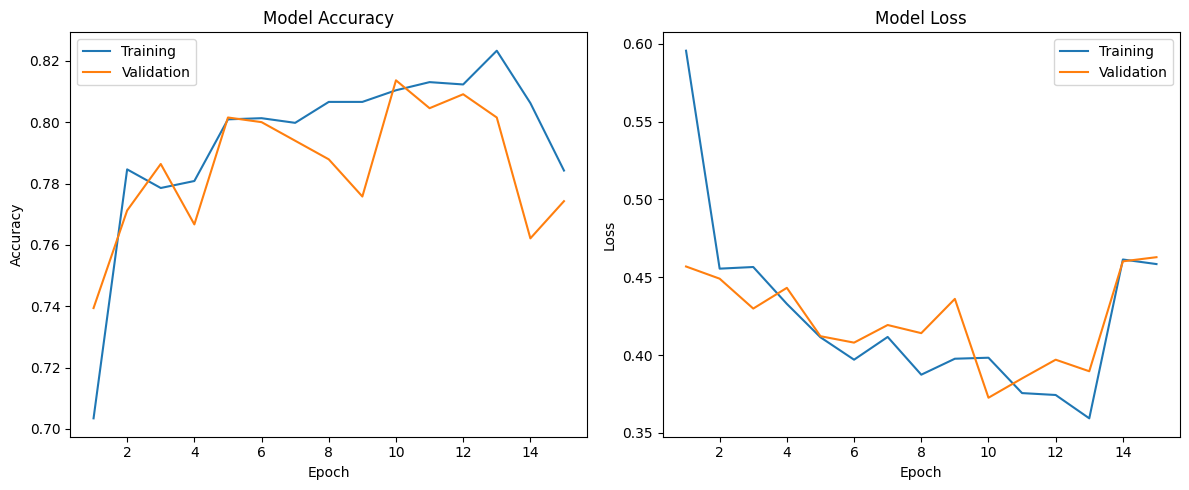

In [6]:
# Plot training history
epochs_completed = range(1, len(history.history['loss']) + 1)

plt.figure(figsize=(12, 5))

# Accuracy subplot
plt.subplot(1, 2, 1)
plt.plot(epochs_completed, history.history['accuracy'], label='Training')
plt.plot(epochs_completed, history.history['val_accuracy'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Model Accuracy')
plt.legend()

# Loss subplot
plt.subplot(1, 2, 2)
plt.plot(epochs_completed, history.history['loss'], label='Training')
plt.plot(epochs_completed, history.history['val_loss'], label='Validation')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Model Loss')
plt.legend()

plt.tight_layout()
plt.show()

**Performance metrics and confusion matrix**

21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step - accuracy: 0.8136 - loss: 0.3726
Test Loss: 0.3726
Test Accuracy: 81.36%

Classification Report:
              precision    recall  f1-score   support

      benign       0.93      0.71      0.81       360
   malignant       0.73      0.94      0.82       300

    accuracy                           0.81       660
   macro avg       0.83      0.82      0.81       660
weighted avg       0.84      0.81      0.81       660



<Figure size 600x600 with 0 Axes>

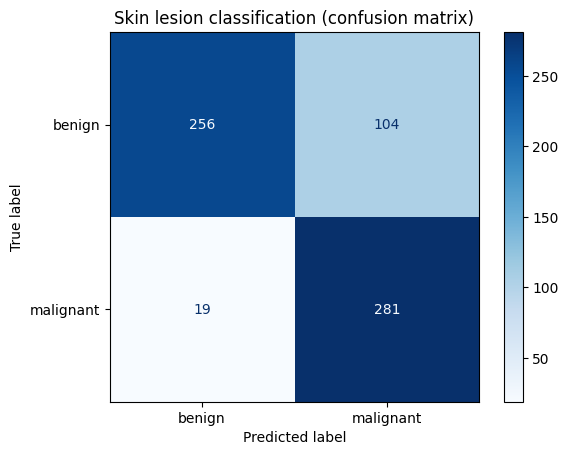

In [7]:
# Evaluate model on test data
test_results = model.evaluate(test_ds, verbose=1)
print(f'Test Loss: {test_results[0]:.4f}')
print(f'Test Accuracy: {test_results[1] * 100:.2f}%')

# Generate predictions
y_true = df_test['label'].values
y_pred_probs = model.predict(test_ds, verbose=0)
y_pred = (y_pred_probs >= 0.5).astype(int).flatten()

class_names = ['benign', 'malignant']

# Print Classification Report (sensitivity and specificity)
print('\nClassification Report:')
print(classification_report(y_true, y_pred, target_names=class_names))

# Plot confusion matrix
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

plt.figure(figsize=(6, 6))
disp.plot(cmap='Blues', values_format='d')
plt.title('Skin lesion classification (confusion matrix)')
plt.show()

In [8]:
# Predictions for 10 sample test images
sample_images = []
sample_labels = []

for images, labels in test_ds.unbatch().take(10):
    sample_images.append(images.numpy())
    sample_labels.append(int(labels.numpy()))

sample_images = np.array(sample_images)
prediction_scores = model.predict(sample_images, verbose=0)

print('\n sample test images predictions vs real')
print('\n ------------------------------------')

for i, score in enumerate(prediction_scores):
    predicted_label = int(score[0] >= 0.5)
    predicted_class = class_names[predicted_label]
    actual_class = class_names[sample_labels[i]]

    print(
        f'Image {i + 1:02d} | '
        f'Predicted: {predicted_class:10s} | '
        f'Actual: {actual_class:10s} | '
        f'Score: {float(score[0]):.3f}'
    )


 sample test images predictions vs real

 ------------------------------------
Image 01 | Predicted: benign     | Actual: benign     | Score: 0.000
Image 02 | Predicted: malignant  | Actual: benign     | Score: 0.509
Image 03 | Predicted: malignant  | Actual: malignant  | Score: 0.612
Image 04 | Predicted: malignant  | Actual: benign     | Score: 0.575
Image 05 | Predicted: malignant  | Actual: malignant  | Score: 0.515
Image 06 | Predicted: benign     | Actual: benign     | Score: 0.007
Image 07 | Predicted: benign     | Actual: benign     | Score: 0.009
Image 08 | Predicted: malignant  | Actual: malignant  | Score: 0.841
Image 09 | Predicted: benign     | Actual: benign     | Score: 0.000
Image 10 | Predicted: benign     | Actual: benign     | Score: 0.212


In [15]:
# Save trained model
model.save('melanoma_custom_cnn_model.keras')
print("Successfully saved")

Successfully saved


**Testing CNN model with external images**

Upload external image(s)


Saving benign_1.jpg to benign_1.jpg
Saving benign_2.jpg to benign_2.jpg
Saving malignant_1.jpg to malignant_1.jpg
Saving malignant_2.jpg to malignant_2.jpg
Saving malignant_3.jpg to malignant_3.jpg
File: benign_1.jpg              | Predicted: benign    (52.21%) | Actual: benign
File: benign_2.jpg              | Predicted: malignant (74.27%) | Actual: benign
File: malignant_1.jpg           | Predicted: malignant (86.22%) | Actual: malignant
File: malignant_2.jpg           | Predicted: malignant (90.45%) | Actual: malignant
File: malignant_3.jpg           | Predicted: malignant (82.08%) | Actual: malignant


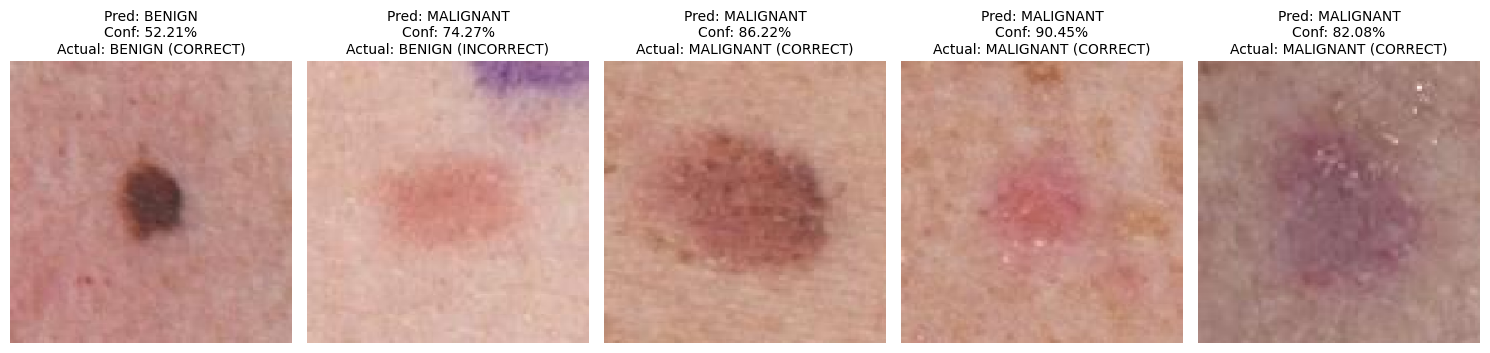


 External Validation Accuracy: 4/5 (80.00%)


In [9]:
print("Upload external image(s)")
uploaded = files.upload()

class_names = ['benign', 'malignant']
correct_predictions = 0
evaluated_with_truth = 0

plt.figure(figsize=(15, 6))

for idx, filename in enumerate(uploaded.keys()):
    # Load ext images and apply resizing (224x224 as the dataset images) and scale Normalization [0, 1]
    img = keras_image.load_img(filename, target_size=(224, 224))
    img_array = keras_image.img_to_array(img)
    display_img = img_array.astype('uint8')

    img_normalized = img_array / 255.0
    img_batch = np.expand_dims(img_normalized, axis=0)

    # Binary classification (Benign or Malignant) and compute confidence score
    pred_prob = model.predict(img_batch, verbose=0)[0][0]
    predicted_label = int(pred_prob >= 0.5)
    predicted_class = class_names[predicted_label]
    confidence = (pred_prob if predicted_label == 1 else 1 - pred_prob) * 100

    # Check ground truth from filename (if named with 'benign' or 'malignant')
    fname_lower = filename.lower()
    if 'malignant' in fname_lower:
        actual_class = 'malignant'
    elif 'benign' in fname_lower:
        actual_class = 'benign'
    else:
        actual_class = 'unknown'

    status_text = ""
    if actual_class != 'unknown':
        evaluated_with_truth += 1
        is_correct = (predicted_class == actual_class)
        if is_correct:
            correct_predictions += 1
        status_text = f"\nActual: {actual_class.upper()} ({'CORRECT' if is_correct else 'INCORRECT'})"

    # Display image alongside prediction and confidence percentage
    plt.subplot(1, len(uploaded), idx + 1)
    plt.imshow(display_img)
    plt.axis('off')
    plt.title(f"Pred: {predicted_class.upper()}\nConf: {confidence:.2f}%{status_text}", fontsize=10)

    print(f"File: {filename:25s} | Predicted: {predicted_class:9s} ({confidence:.2f}%) | Actual: {actual_class}")

plt.tight_layout()
plt.show()

if evaluated_with_truth > 0:
    ext_acc = (correct_predictions / evaluated_with_truth) * 100
    print(f"\n External Validation Accuracy: {correct_predictions}/{evaluated_with_truth} ({ext_acc:.2f}%)")